In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load RFM data
rfm = pd.read_csv("../data/rfm.csv")
rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


In [2]:
print(rfm.shape)
rfm.describe()

(4338, 4)


,CustomerID,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000,4338.000000
mean,15300.408022,92.536422,4.272015,2048.688081
std,1721.808492,100.014169,7.697998,8985.230220
min,12346.000000,1.000000,1.000000,3.750000
25%,13813.250000,18.000000,1.000000,306.482500
50%,15299.500000,51.000000,2.000000,668.570000
75%,16778.750000,142.000000,5.000000,1660.597500
max,18287.000000,374.000000,209.000000,280206.020000


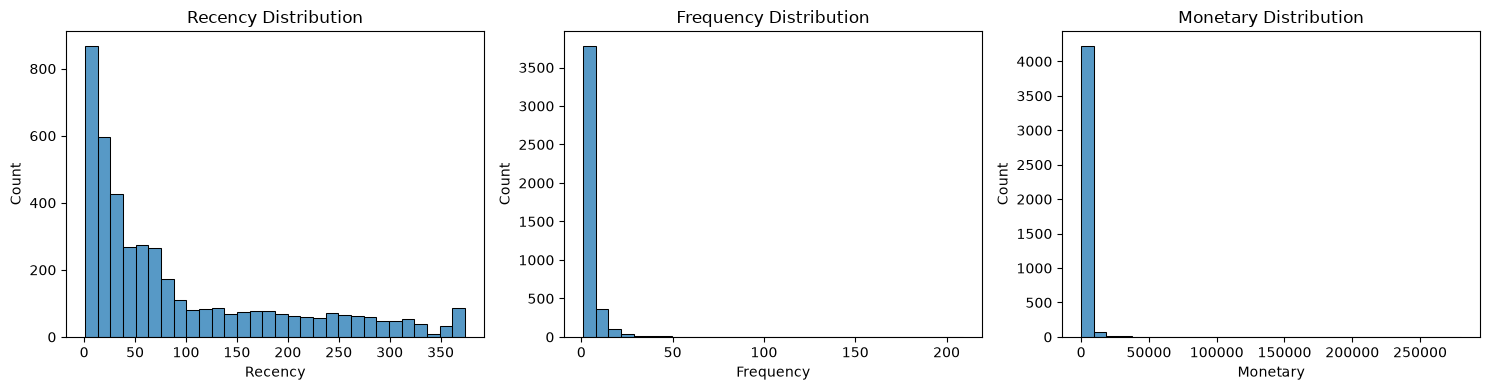

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(rfm["Recency"], bins=30, ax=axes[0])
axes[0].set_title("Recency Distribution")

sns.histplot(rfm["Frequency"], bins=30, ax=axes[1])
axes[1].set_title("Frequency Distribution")

sns.histplot(rfm["Monetary"], bins=30, ax=axes[2])
axes[2].set_title("Monetary Distribution")

plt.tight_layout()
plt.show()

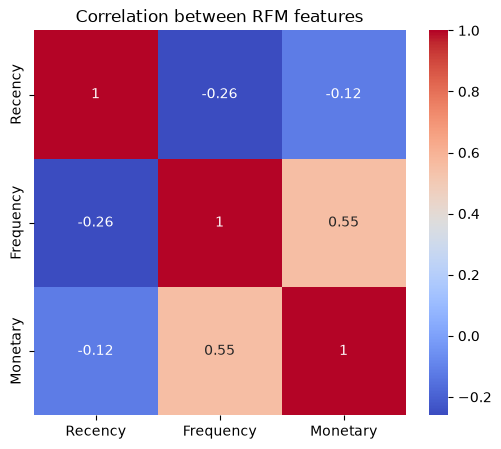

In [6]:
plt.figure(figsize=(6, 5))
sns.heatmap(rfm[["Recency", "Frequency", "Monetary"]].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation between RFM features")
plt.show()

In [8]:
from sklearn.preprocessing import StandardScaler

# Select the RFM columns
X = rfm[["Recency", "Frequency", "Monetary"]]

# Scale them so they're on the same numeric range
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data sample:")
print(X_scaled[:5])

Scaled data sample:
[[ 2.33457414 -0.4250965   8.36301037]
 [-0.90534032  0.3544168   0.2516989 ]
 [-0.17535959 -0.03533985 -0.02798783]
 [-0.73534481 -0.4250965  -0.03240559]
 [ 2.17457836 -0.4250965  -0.19081155]]


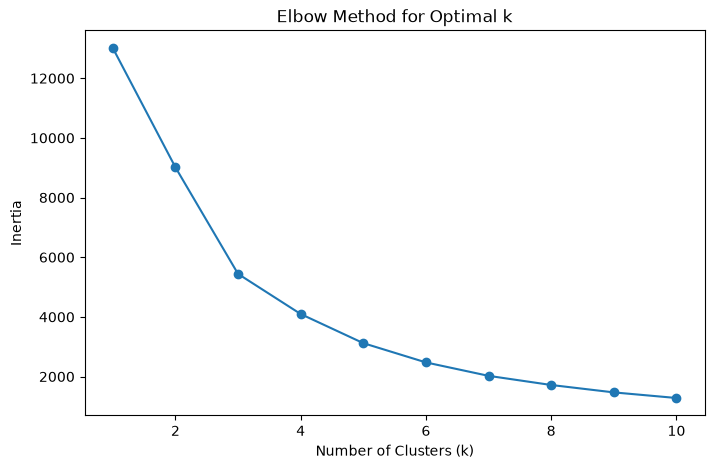

In [10]:
from sklearn.cluster import KMeans

inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.show()

In [11]:
from sklearn.metrics import silhouette_score

for k in range(2, 8):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print(f"k={k}, Silhouette Score={score:.3f}")

k=2, Silhouette Score=0.896
k=3, Silhouette Score=0.594
k=4, Silhouette Score=0.616
k=5, Silhouette Score=0.617
k=6, Silhouette Score=0.598
k=7, Silhouette Score=0.517


In [12]:
# Final clustering with k=4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["Segment"] = kmeans.fit_predict(X_scaled)

print(rfm["Segment"].value_counts())
rfm.groupby("Segment")[["Recency", "Frequency", "Monetary"]].mean()

Segment
0    3054
1    1067
3     204
2      13
Name: count, dtype: int64


,Recency,Frequency,Monetary
Segment,,,
0,43.702685,3.682711,1353.625312
1,248.075914,1.552015,478.848773
2,7.384615,82.538462,127187.959231
3,15.500000,22.333333,12690.500392
